# Forma de la duración de cuatro ensayos

Revisión visual del bloque «Generador: duraciones BetaPERT» (`docs/Generador_de_datos.docx`, sección 1.8).
Simula cuatro ensayos de complejidad media, con cuatro soluciones y un analista intermedio, y compara la
duración con tres formas:

- **λ = 4**: la PERT clásica del anteproyecto, la que usa `muestrear_ensayo` por omisión.
- **Propuesta**: λ = 1 en las tareas triangulares y λ = 0 en las uniformes (sección 1.10 del documento).
- **Fuente**: las distribuciones de Costigliola et al. (2017, Tabla 3), triangulares y uniformes. La corrida
  de HPLC, que la fuente da determinista, es la triangular del supuesto S05, y la de los métodos de tramo, la
  distribución de la técnica recortada a su tramo (S15).

Todavía no incluye la preparación ni la idoneidad del sistema, cuyos tres puntos se fijan después.
Guarda la figura en `resultados/figuras/` y las tablas en `resultados/tablas/`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
from src.generador import duraciones as du, parametros, registro

ENSAYOS = ["M02", "M07", "M10", "M11"]
N_SOLUCIONES = 4      # el máximo de la complejidad media (S08)
N = 400_000           # ejecuciones simuladas por ensayo y forma
SEMILLA = 2026
FIGURA = RAIZ / "resultados" / "figuras" / "forma_cuatro_ensayos.png"
TABLA = RAIZ / "resultados" / "tablas" / "forma_cuatro_ensayos.csv"
TABLA_DISTANCIA = RAIZ / "resultados" / "tablas" / "distancia_a_la_fuente.csv"
TABLA_TRAMOS = RAIZ / "resultados" / "tablas" / "corrida_metodos_de_tramo.csv"

catalogo = parametros.cargar_hoja("Catálogo").set_index("ID")
hoja = parametros.cargar_hoja("Duraciones")
CAMPO = {"Preparación de muestra": "t_preparacion", "Montaje del equipo": "t_montaje",
         "Corrida": "t_corrida", "Procesamiento de datos": "t_procesamiento"}
hoja = hoja[hoja["Tarea"].isin(list(CAMPO))].set_index(["Técnica", "Tarea"]).sort_index()

## Las tres formas

La propuesta usa el parámetro `forma` de `muestrear_ensayo` con un valor por tarea. La fuente se simula aquí,
solo para comparar: cada tarea con su distribución original y la preparación como el tiempo por solución por el
número de soluciones, igual que en el generador.

In [2]:
def forma_propuesta(metodo):
    """λ = 1 en las tareas triangulares y λ = 0 en las que la fuente da uniformes."""
    tecnica = catalogo.at[metodo, "Técnica"]
    return {CAMPO[t]: 0.0 if str(hoja.loc[(tecnica, t), "Distribución original"]).startswith("U") else 1.0
            for t in CAMPO}


def tarea_fuente(tecnica, tarea, n, rng, cuantiles=(0.0, 1.0)):
    """Distribución de la fuente para una tarea, recortada a un tramo de cuantiles."""
    f = hoja.loc[(tecnica, tarea)]
    a, m, b = float(f["a (mín)"]), float(f["m (moda)"]), float(f["b (máx)"])
    u = rng.uniform(*cuantiles, size=n)
    if str(f["Distribución original"]).startswith("U"):
        return a + (b - a) * u
    return stats.triang.ppf(u, (m - a) / (b - a), loc=a, scale=b - a)


def muestrear_fuente(metodo, n_soluciones, n, rng):
    """Tareas y duración de un ensayo con las distribuciones de la fuente y un analista intermedio."""
    fila = catalogo.loc[metodo]
    tecnica = fila["Técnica"]
    if pd.notna(fila["Corrida moda (min)"]):    # HPLC y GC: triangular del supuesto S05
        corrida = rng.triangular(fila["Corrida mín (min)"], fila["Corrida moda (min)"], fila["Corrida máx (min)"], n)
    else:                                        # PSA, KF, DSC y XRPD: tramo de la técnica (S15)
        corrida = tarea_fuente(tecnica, "Corrida", n, rng, (fila["Cuantil desde"], fila["Cuantil hasta"]))
    t = pd.DataFrame({"t_preparacion": n_soluciones * tarea_fuente(tecnica, "Preparación de muestra", n, rng),
                      "t_montaje": tarea_fuente(tecnica, "Montaje del equipo", n, rng),
                      "t_corrida": corrida,
                      "t_procesamiento": tarea_fuente(tecnica, "Procesamiento de datos", n, rng)})
    t.insert(0, "duracion_simulada", t.sum(axis=1))
    return t


FORMAS = ["λ = 4", "Propuesta", "Fuente"]
simulado = {}
for metodo in ENSAYOS:
    simulado[metodo] = {
        "λ = 4": du.muestrear_ensayo(metodo, N_SOLUCIONES, n=N, rng=SEMILLA),
        "Propuesta": du.muestrear_ensayo(metodo, N_SOLUCIONES, n=N, rng=SEMILLA, forma=forma_propuesta(metodo)),
        "Fuente": muestrear_fuente(metodo, N_SOLUCIONES, N, np.random.default_rng(SEMILLA)),
    }
    # control: la corrida simulada de la fuente reproduce la media del catálogo
    assert np.isclose(simulado[metodo]["Fuente"]["t_corrida"].mean(), catalogo.at[metodo, "Corrida promedio (min)"], rtol=0.01)
{m: forma_propuesta(m) for m in ENSAYOS}

{'M02': {'t_preparacion': 1.0,
  't_montaje': 1.0,
  't_corrida': 1.0,
  't_procesamiento': 1.0},
 'M07': {'t_preparacion': 1.0,
  't_montaje': 1.0,
  't_corrida': 1.0,
  't_procesamiento': 1.0},
 'M10': {'t_preparacion': 1.0,
  't_montaje': 1.0,
  't_corrida': 0.0,
  't_procesamiento': 1.0},
 'M11': {'t_preparacion': 1.0,
  't_montaje': 1.0,
  't_corrida': 1.0,
  't_procesamiento': 1.0}}

## Resumen de cada forma

Minutos. Los tres puntos son los del registro (`registro.tres_puntos`). La última columna dice qué tarea
aporta más a la varianza de la duración.

In [3]:
def resumen(metodo, forma, t):
    d = t["duracion_simulada"]
    varianza = t[list(CAMPO.values())].var()
    optimista, mas_probable, pesimista = registro.tres_puntos(metodo, N_SOLUCIONES)
    return {"Ensayo": metodo, "Técnica": catalogo.at[metodo, "Técnica"], "Nombre": catalogo.at[metodo, "Ensayo"],
            "Forma": forma, "Optimista": optimista, "Más probable": mas_probable, "Pesimista": pesimista,
            "Media": d.mean(), "Desviación": d.std(), "Asimetría": stats.skew(d),
            "P5": d.quantile(0.05), "P50": d.median(), "P95": d.quantile(0.95),
            "Mínimo": d.min(), "Máximo": d.max(),
            "Tarea con más varianza": varianza.idxmax(), "Parte de la varianza": varianza.max() / varianza.sum()}


tabla = pd.DataFrame([resumen(m, f, simulado[m][f]) for m in ENSAYOS for f in FORMAS])
tabla.to_csv(TABLA, index=False)
tabla.drop(columns=["Nombre", "Mínimo", "Máximo"]).round(2)

,Ensayo,Técnica,Forma,Optimista,Más probable,Pesimista,Media,Desviación,Asimetría,P5,P50,P95,Tarea con más varianza,Parte de la varianza
0,M02,HPLC,λ = 4,171.57,370.72,661.86,386.01,72.14,0.22,274.32,382.19,510.59,t_preparacion,0.96
1,M02,HPLC,Propuesta,171.57,370.72,661.86,401.18,96.56,0.13,252.98,397.31,562.78,t_preparacion,0.96
2,M02,HPLC,Fuente,171.57,370.72,661.86,401.39,79.84,0.23,277.49,395.06,542.17,t_preparacion,0.96
3,M07,KF,λ = 4,20.00,57.00,170.54,69.71,17.67,0.47,44.17,67.79,101.81,t_preparacion,0.89
4,M07,KF,Propuesta,20.00,57.00,170.54,82.41,24.90,0.27,45.45,80.33,125.74,t_preparacion,0.90
5,M07,KF,Fuente,20.00,57.00,170.54,85.12,22.04,0.39,53.03,82.54,124.88,t_preparacion,0.88
6,M10,DSC,λ = 4,67.80,163.40,328.00,174.84,31.35,0.09,123.96,174.45,227.19,t_corrida,0.69
7,M10,DSC,Propuesta,67.80,163.40,328.00,186.42,46.73,0.05,110.44,186.33,263.77,t_corrida,0.72
8,M10,DSC,Fuente,67.80,163.40,328.00,186.23,45.21,0.05,113.29,186.20,260.15,t_corrida,0.77
9,M11,XRPD,λ = 4,34.00,77.00,246.01,97.93,21.38,0.45,66.06,96.03,136.32,t_corrida,0.66


## Figura

Es la Figura 1 del documento (sección 1.8). El eje horizontal de cada panel va del tiempo optimista al pesimista
del registro, y la línea vertical marca el más probable; la escala vertical cambia de un panel a otro.

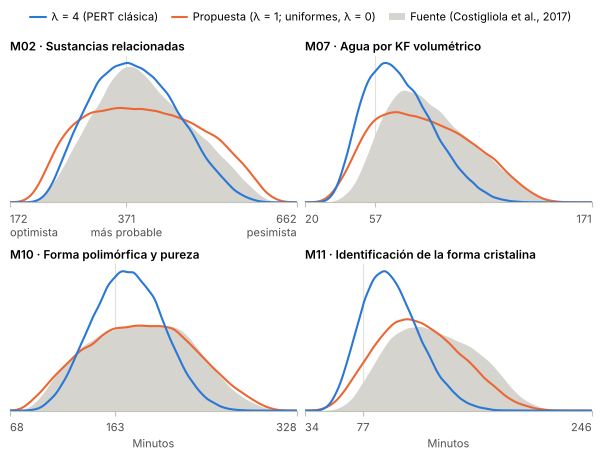

In [4]:
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Inter", "Helvetica", "Arial", "Liberation Sans", "DejaVu Sans"],
    "font.size": 8, "axes.titlesize": 8.5, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.edgecolor": "#c3c2b7", "axes.linewidth": 0.8, "xtick.color": "#c3c2b7", "xtick.labelcolor": "#52514e",
    "axes.labelcolor": "#52514e", "figure.facecolor": "white", "axes.facecolor": "white",
})
COLOR = {"λ = 4": "#2a78d6", "Propuesta": "#eb6834", "Fuente": "#d6d4ce"}
ETIQUETA = {"λ = 4": "λ = 4 (PERT clásica)", "Propuesta": "Propuesta (λ = 1; uniformes, λ = 0)",
            "Fuente": "Fuente (Costigliola et al., 2017)"}


def densidad(x, malla, n=100_000):
    """Densidad suavizada (núcleo gaussiano) con las primeras n ejecuciones, que son independientes."""
    return stats.gaussian_kde(np.asarray(x)[:n])(malla)


fig, ejes = plt.subplots(2, 2, figsize=(5.9, 4.5), layout="constrained")
for eje, metodo in zip(ejes.flat, ENSAYOS):
    a, m, b = registro.tres_puntos(metodo, N_SOLUCIONES)
    malla = np.linspace(a, b, 400)
    eje.axvline(m, color="#e1e0d9", linewidth=0.8, zorder=0)
    for forma in ("Fuente", "Propuesta", "λ = 4"):
        y = densidad(simulado[metodo][forma]["duracion_simulada"], malla)
        if forma == "Fuente":
            eje.fill_between(malla, y, color=COLOR[forma], linewidth=0, label=ETIQUETA[forma], zorder=1)
        else:
            eje.plot(malla, y, color=COLOR[forma], linewidth=1.5, label=ETIQUETA[forma],
                     solid_joinstyle="round", solid_capstyle="round", zorder=2)
    eje.set_xlim(a, b)
    eje.set_ylim(bottom=0)
    nombres = ["\noptimista", "\nmás probable", "\npesimista"] if metodo == ENSAYOS[0] else ["", "", ""]   # la clave va en el primero
    eje.set_xticks([a, m, b], [f"{x:.0f}{t}" for x, t in zip((a, m, b), nombres)])
    etiquetas = eje.get_xticklabels()
    etiquetas[0].set_horizontalalignment("left")
    etiquetas[-1].set_horizontalalignment("right")
    eje.set_yticks([])
    for lado in ("top", "right", "left"):
        eje.spines[lado].set_visible(False)
    eje.set_title(f"{metodo} · {catalogo.at[metodo, 'Ensayo']}", pad=4)
for eje in ejes[1]:
    eje.set_xlabel("Minutos", labelpad=2)
mano, nombre = ejes[0, 0].get_legend_handles_labels()
orden = [nombre.index(ETIQUETA[f]) for f in FORMAS]
fig.legend([mano[i] for i in orden], [nombre[i] for i in orden], loc="outside upper center", ncols=3,
           frameon=False, handlelength=1.4, handletextpad=0.5, columnspacing=1.2)
fig.savefig(FIGURA, dpi=300)
plt.show()

## Distancia a la fuente en los doce ensayos

Cada ensayo con el máximo de soluciones de su complejidad. La distancia es la de Wasserstein entre la duración
simulada y la de la fuente: cuántos minutos, en promedio, habría que mover las duraciones simuladas para que su
distribución coincida con la de la fuente. Va como fracción de la media de la fuente, igual que las diferencias
de media y de desviación.

In [5]:
def comparar(metodo):
    n_sol = int(catalogo.at[metodo, "Soluciones máx"])
    fuente = muestrear_fuente(metodo, n_sol, N, np.random.default_rng(SEMILLA))["duracion_simulada"]
    fila = {"Ensayo": metodo, "Técnica": catalogo.at[metodo, "Técnica"], "Soluciones": n_sol,
            "Media fuente": fuente.mean(), "Desviación fuente": fuente.std()}
    for nombre, forma in (("λ = 4", du.FORMA_PERT), ("Propuesta", forma_propuesta(metodo))):
        d = du.muestrear_ensayo(metodo, n_sol, n=N, rng=SEMILLA, forma=forma)["duracion_simulada"]
        fila[f"Media, {nombre}"] = d.mean() / fuente.mean() - 1
        fila[f"Desviación, {nombre}"] = d.std() / fuente.std() - 1
        fila[f"Distancia, {nombre}"] = stats.wasserstein_distance(d, fuente) / fuente.mean()
    return fila


distancia = pd.DataFrame([comparar(m) for m in catalogo.index])
distancia.to_csv(TABLA_DISTANCIA, index=False)
print("Distancia promedio:", distancia[["Distancia, λ = 4", "Distancia, Propuesta"]].mean().round(3).to_dict())
distancia.round(3)

Distancia promedio: {'Distancia, λ = 4': 0.112, 'Distancia, Propuesta': 0.027}


,Ensayo,Técnica,Soluciones,Media fuente,Desviación fuente,"Media, λ = 4","Desviación, λ = 4","Distancia, λ = 4","Media, Propuesta","Desviación, Propuesta","Distancia, Propuesta"
0,M01,HPLC,2,211.303,40.401,-0.033,-0.097,0.034,-0.001,0.209,0.039
1,M02,HPLC,4,401.395,79.844,-0.038,-0.096,0.039,-0.001,0.209,0.041
2,M03,GC,2,116.766,16.716,-0.110,-0.205,0.110,-0.001,0.130,0.016
3,M04,GC,4,173.146,28.511,-0.113,-0.214,0.113,-0.001,0.124,0.019
4,M05,PSA,2,54.392,11.613,-0.068,-0.293,0.077,-0.009,0.047,0.012
5,M06,PSA,4,85.263,17.249,-0.121,-0.270,0.121,0.000,0.076,0.014
6,M07,KF,4,85.121,22.041,-0.181,-0.198,0.181,-0.032,0.130,0.037
7,M08,KF,6,128.351,32.213,-0.155,-0.199,0.155,-0.001,0.134,0.032
8,M09,DSC,2,72.369,14.385,-0.090,-0.245,0.090,0.001,0.089,0.015
9,M10,DSC,4,186.233,45.209,-0.061,-0.307,0.080,0.001,0.034,0.006


## La corrida de los métodos de tramo

En PSA, KF, DSC y XRPD cada método toma un tramo de la distribución de la técnica (S15). La BetaPERT del
registro usa el tramo como mínimo y máximo y la moda de la técnica dentro de él; esta tabla compara su media
con la del tramo de la fuente, que es la columna «Corrida promedio» del catálogo.

In [6]:
filas = []
for metodo in catalogo.index[catalogo["Corrida moda (min)"].isna()]:
    a, m, b = registro.corrida_tres_puntos(metodo)
    filas.append({"Ensayo": metodo, "Técnica": catalogo.at[metodo, "Técnica"],
                  "Tramo de cuantiles": f"{catalogo.at[metodo, 'Cuantil desde']:.2f}–{catalogo.at[metodo, 'Cuantil hasta']:.2f}",
                  "Mínimo": a, "Moda": m, "Máximo": b,
                  "Media del tramo (fuente)": catalogo.at[metodo, "Corrida promedio (min)"],
                  "Media λ = 4": du.media_betapert(a, m, b), "Media λ = 1": du.media_betapert(a, m, b, forma=1)})
tramos = pd.DataFrame(filas)
tramos.to_csv(TABLA_TRAMOS, index=False)
tramos.round(2)

,Ensayo,Técnica,Tramo de cuantiles,Mínimo,Moda,Máximo,Media del tramo (fuente),Media λ = 4,Media λ = 1
0,M05,PSA,0.00–0.36,5.00,10.00,12.14,9.55,9.52,9.05
1,M06,PSA,0.36–1.00,12.14,12.14,30.00,18.09,15.12,18.09
2,M07,KF,0.00–0.64,2.00,5.00,24.54,13.13,7.76,10.51
3,M08,KF,0.64–1.00,24.54,24.54,56.00,35.03,29.78,35.03
4,M09,DSC,0.00–0.18,12.00,27.40,42.80,27.40,27.40,27.40
5,M10,DSC,0.18–1.00,42.80,111.40,180.00,111.40,111.40,111.40
6,M11,XRPD,0.00–0.78,11.00,25.00,116.01,61.08,37.83,50.67
7,M12,XRPD,0.78–1.00,116.01,116.01,203.00,145.01,130.51,145.01
